Recommendation systems are a collection of algorithms used to recommend items to users based on information taken from the user. These systems have become ubiquitous and can be commonly seen in online stores, movie databases and job finders. In this notebook, we will explore recommendation systems based on **Collaborative Filtering** and implement one using Python, **pandas** and **NumPy**.

Collaborative filtering never looks at what a movie *is* (its genres, actors or plot). It only looks at **who rated what, and how**. The idea is simple: people who agreed with you in the past will probably agree with you in the future.

First, let's get all of the imports out of the way:

In [1]:
# Dataframe manipulation library
import pandas as pd
# Numerical functions (minimum, absolute value, error-state control)
import numpy as np
# Plotting the distribution of user similarities
import matplotlib.pyplot as plt
# Builds file paths that work on Windows, macOS and Linux
from pathlib import Path

Now let's read each file into its own DataFrame. These are exactly the same files as lesson 15, so instead of keeping a second copy, `DATA_DIR` points to lesson 15's `data/` folder, which holds **movies.csv** and **ratings_sample.csv.gz** (the ratings compressed with gzip, which pandas reads directly), and the `/` operator of `pathlib.Path` joins the folder and the file name.

In [2]:
# Lesson 15 uses the same MovieLens files, so they are stored once, in lesson 15's folder
DATA_DIR = Path("../15-content-based-recommender/data")

movies_df = pd.read_csv(DATA_DIR / "movies.csv")
# The ratings file is gzip-compressed (26 MB instead of 102 MB); pandas reads it directly
ratings_df = pd.read_csv(DATA_DIR / "ratings_sample.csv.gz")

In [3]:
movies_df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
movies_df.shape

(34208, 3)

In [5]:
movies_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34208 entries, 0 to 34207
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  34208 non-null  int64 
 1   title    34208 non-null  object
 2   genres   34208 non-null  object
dtypes: int64(1), object(2)
memory usage: 801.9+ KB


So each movie has a unique ID, a title with its release year along with it (which may contain unicode characters) and several different genres in the same field. Let's move the year out of the title and into its own **year** column, using pandas' string functions `str.extract` and `str.replace`.

The year is copied out first, while it is still part of the title, and then removed from the title. Every pattern is written as a raw string (`r'...'`), so Python passes `\d` and `\(` to the regular-expression engine untouched.

In [6]:
# 1) Capture the 4 digits that sit between parentheses, e.g. '(1995)' -> '1995'.
#    The parentheses in the pattern keep us from grabbing numbers that belong to a title, like '2001: A Space Odyssey'.
movies_df['year'] = movies_df['title'].str.extract(r'\((\d{4})\)', expand=False)

# Store the year as a nullable integer (Int64): movies without a year keep <NA>
movies_df['year'] = pd.to_numeric(movies_df['year'], errors='coerce').astype('Int64')

# 2) Remove '(YYYY)' from the title. regex=True tells pandas the pattern is a regular expression.
movies_df['title'] = movies_df['title'].str.replace(r'\(\d{4}\)', '', regex=True)

# 3) Remove any whitespace left at the beginning or the end of the title
movies_df['title'] = movies_df['title'].str.strip()

In [7]:
movies_df.head()

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995
1,2,Jumanji,Adventure|Children|Fantasy,1995
2,3,Grumpier Old Men,Comedy|Romance,1995
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995
4,5,Father of the Bride Part II,Comedy,1995


With that, let's also drop the genres column since we won't need it for this particular recommendation system: collaborative filtering only uses ratings.

In [8]:
# drop(columns=...) removes the named column(s) and returns a new DataFrame
movies_df = movies_df.drop(columns='genres')

Here's the final movies dataframe:

In [9]:
movies_df.head()

,movieId,title,year
0,1,Toy Story,1995
1,2,Jumanji,1995
2,3,Grumpier Old Men,1995
3,4,Waiting to Exhale,1995
4,5,Father of the Bride Part II,1995


Next, let's look at the ratings dataframe.

In [10]:
ratings_df.head()

,userId,movieId,rating,timestamp
0,1,169,2.5,1204927694
1,1,2471,3.0,1204927438
2,1,48516,5.0,1204927435
3,2,2571,3.5,1436165433
4,2,109487,4.0,1436165496


Every row in the ratings dataframe has a user id associated with at least one movie, a rating and a timestamp showing when they reviewed it. We won't be needing the timestamp column, so let's drop it to save on memory.

In [11]:
# Remove the timestamp column; only userId, movieId and rating are needed
ratings_df = ratings_df.drop(columns='timestamp')

In [12]:
ratings_df.head()

,userId,movieId,rating
0,1,169,2.5
1,1,2471,3.0
2,1,48516,5.0
3,2,2571,3.5
4,2,109487,4.0


A quick look at the size of the data: how many ratings, users and movies we are working with.

In [13]:
print('ratings:', len(ratings_df))
print('users  :', ratings_df['userId'].nunique())
print('movies :', ratings_df['movieId'].nunique())

ratings: 3899999
users  : 42130
movies : 23648


# Collaborative Filtering

Now it's time to start our work on recommendation systems.

The technique we're going to look at is called **Collaborative Filtering**, and the variant used here is **User-User Filtering**. As hinted by its name, this technique uses other users to recommend items to the input user. It finds users that have similar preferences and opinions as the input and then recommends items that they have liked. There are several methods of finding similar users (some of them using Machine Learning), and the one we will use here is based on the **Pearson Correlation Coefficient**.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%205/images/User_Item.png" width=800px>

The process for creating a User Based recommendation system is as follows:

*   Select a user with the movies the user has watched
*   Based on their ratings of those movies, find the top X neighbours
*   Get the watched movie record of the user for each neighbour
*   Calculate a similarity score using some formula
*   Recommend the items with the highest score

Let's begin by creating an input user to recommend movies to:

Notice: To add more movies, simply increase the amount of elements in the `userInput`. Feel free to add more in! Title matching ignores upper/lower case. If a movie starts with "The", like "The Matrix", write it the way the dataset stores it: 'Matrix, The'.

In [14]:
userInput = [
            {'title':'Breakfast Club, The', 'rating':5},
            {'title':'Toy Story', 'rating':3.5},
            {'title':'Jumanji', 'rating':2},
            {'title':"Pulp Fiction", 'rating':5},
            {'title':'Akira', 'rating':4.5}
         ]
inputMovies = pd.DataFrame(userInput)
inputMovies

,title,rating
0,"Breakfast Club, The",5.0
1,Toy Story,3.5
2,Jumanji,2.0
3,Pulp Fiction,5.0
4,Akira,4.5


#### Add movieId to input user

With the input complete, let's look up each input movie's ID in the movies dataframe and add it to the input.

Both sides get a lower-case copy of the title (a `key` column), and the two tables are merged on that key with `on='key'`. A **left** merge keeps every input row, so a title that doesn't exist in the dataset shows up with an empty movieId; we print those titles and then remove them.

In [15]:
# Lookup table: movieId + title + a lower-case 'key' to match on
lookup = movies_df[['movieId', 'title']].assign(key=movies_df['title'].str.lower())
# If two movies share the same title, keep the first one so each input matches exactly one movie
lookup = lookup.drop_duplicates(subset='key')

# The same lower-case key for the input titles
inputMovies['key'] = inputMovies['title'].str.lower().str.strip()

# Left merge: every input row stays; unmatched titles get NaN as movieId
inputMovies = inputMovies.drop(columns='title').merge(lookup, on='key', how='left')

# Report and remove titles that were not found
missing = inputMovies[inputMovies['movieId'].isna()]
if not missing.empty:
    print('Not found (check spelling):', missing['key'].tolist())
inputMovies = inputMovies.dropna(subset=['movieId'])

# Integer ids, no helper column, readable column order
inputMovies['movieId'] = inputMovies['movieId'].astype(int)
inputMovies = inputMovies[['movieId', 'title', 'rating']].reset_index(drop=True)

# Final input dataframe
inputMovies

,movieId,title,rating
0,1968,"Breakfast Club, The",5.0
1,1,Toy Story,3.5
2,2,Jumanji,2.0
3,296,Pulp Fiction,5.0
4,1274,Akira,4.5


#### The users who have seen the same movies

Now with the movie IDs in our input, we can get the subset of users that have watched and reviewed the movies in our input.

In [16]:
# Keep only the ratings that belong to one of the input movies
userSubset = ratings_df[ratings_df['movieId'].isin(inputMovies['movieId'])]
userSubset.head()

,userId,movieId,rating
19,4,296,4.0
441,12,1968,3.0
479,13,2,2.0
531,13,1274,5.0
681,14,296,2.0


In [17]:
# How many different users rated at least one of the input movies
userSubset['userId'].nunique()

19795

We now group the rows by user ID. Passing the column name as a plain string (`'userId'`) makes each group key a single number, so a group can be fetched with `get_group(<userId>)`.

In [18]:
# groupby splits the table into one sub-table per user
userSubsetGroup = userSubset.groupby('userId')

Let's look at one of the users, e.g. the one with userId=1130.

In [19]:
# All the input movies that user 1130 has rated
userSubsetGroup.get_group(1130)

,userId,movieId,rating
104167,1130,1,0.5
104168,1130,2,4.0
104214,1130,296,4.0
104363,1130,1274,4.5
104443,1130,1968,4.5


Let's also rank the users by how many movies they have in common with the input. The more movies two users share, the more evidence we have about whether their tastes match.

`size()` counts the rows in each group, which here is the number of shared movies per user.

In [20]:
# Number of input movies each user has rated, largest first
# kind='stable' keeps tied users in userId order, so the ranking is the same on every run
commonCounts = userSubsetGroup.size().sort_values(ascending=False, kind='stable')
# How many users share 1, 2, 3, 4 or 5 movies with the input
commonCounts.value_counts().sort_index()

1    11132
2     5075
3     2344
4     1000
5      244
Name: count, dtype: int64

Now let's look at the first users in that ranking.

In [21]:
# Ratings of the three users that share the most movies with the input
firstUsers = commonCounts.index[:3]
userSubset[userSubset['userId'].isin(firstUsers)].sort_values(['userId', 'movieId'])

,userId,movieId,rating
7507,75,1,5.0
7508,75,2,3.5
7540,75,296,5.0
7633,75,1274,4.5
7673,75,1968,5.0
9083,106,1,2.5
9084,106,2,3.0
9115,106,296,3.5
9198,106,1274,3.0
9238,106,1968,3.5


#### Similarity of users to input user

Next, we measure how similar each user is to the input user through the **Pearson Correlation Coefficient**. It measures the strength of a linear association between two variables. For two users with $n$ movies in common, with ratings $x_i$ (input user) and $y_i$ (other user):

$$
r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\;\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}
$$

**Why Pearson Correlation?**

Pearson correlation is invariant to scaling, i.e. multiplying all elements by a positive constant or adding any constant to all elements. For example, if you have two vectors X and Y, then pearson(X, Y) == pearson(X, 2 \* Y + 3). This is an important property in recommendation systems: two users might use the rating scale very differently (one gives 3–5, another gives 1–3), yet still have the same ideas about which movies are better and which are worse.

The values vary from r = -1 to r = 1. A value of 1 is a perfect positive correlation (the two users have similar tastes), 0 means no linear relation, and -1 is a perfect negative correlation (opposite tastes).

We will select the subset of users to compare. Pearson correlation needs **at least 3 shared movies** to say something meaningful: with only 2 points, any two users always get exactly +1 or -1, because two points always lie on a straight line. So we keep the users who rated at least `MIN_COMMON` of the input movies.

In [22]:
# Minimum number of shared movies for a user to be compared with the input
MIN_COMMON = 3

candidateUsers = commonCounts[commonCounts >= MIN_COMMON].index
userSubset = userSubset[userSubset['userId'].isin(candidateUsers)]
print('users compared with the input:', len(candidateUsers))

users compared with the input: 3588


Now we calculate the Pearson Correlation between the input user and every candidate user, all at once.

1. `pivot` turns the ratings into a table with **one row per user and one column per input movie**. A cell is empty (NaN) when that user hasn't rated that movie.
2. The input user's ratings become a Series indexed by `movieId`, so its labels match the table's columns.
3. `corrwith(..., axis=1)` computes the Pearson correlation of every row with the input Series. For each user it uses only the movies both have rated (empty cells are skipped).

A user who gives the same rating to every shared movie has zero variance, so the correlation is undefined (NaN). `np.errstate` silences NumPy's divide warning for those users, and `dropna()` removes them.

In [23]:
# 1) users x input-movies rating table
userMovieMatrix = userSubset.pivot(index='userId', columns='movieId', values='rating')

# 2) the input user's ratings, indexed by movieId
inputRatings = inputMovies.set_index('movieId')['rating']

# 3) Pearson correlation of every user (row) with the input user
with np.errstate(divide='ignore', invalid='ignore'):
    pearsonSeries = userMovieMatrix.corrwith(inputRatings, axis=1)

pearsonSeries = pearsonSeries.dropna()
pearsonSeries.head()

userId
15   -1.000000
17   -0.345857
34    0.981981
39   -0.500000
50   -0.500000
dtype: float64

A correlation based on 3 shared movies is much less trustworthy than one based on 5. **Significance weighting** scales each similarity by how much evidence supports it:

$$
\text{similarity} = r \times \frac{\min(n_{\text{common}},\ \gamma)}{\gamma}
$$

where $\gamma$ is the number of movies needed for full confidence. Here $\gamma$ is the number of input movies, so a user who shares all of them keeps the full correlation, and a user who shares 3 out of 5 keeps 60% of it.

In [24]:
# Number of shared movies for every user that has a similarity value
nCommon = userMovieMatrix.notna().sum(axis=1).loc[pearsonSeries.index]

# Full confidence when the user shares all the input movies
GAMMA = len(inputMovies)

pearsonDF = pd.DataFrame({
    'userId': pearsonSeries.index,
    'similarityIndex': pearsonSeries * np.minimum(nCommon, GAMMA) / GAMMA,
    'nCommon': nCommon,
}).reset_index(drop=True)

pearsonDF.head()

,userId,similarityIndex,nCommon
0,15,-0.600000,3
1,17,-0.276686,4
2,34,0.589188,3
3,39,-0.300000,3
4,50,-0.300000,3


A histogram shows how the similarities are spread: users on the right have tastes close to the input user, users on the left have opposite tastes.

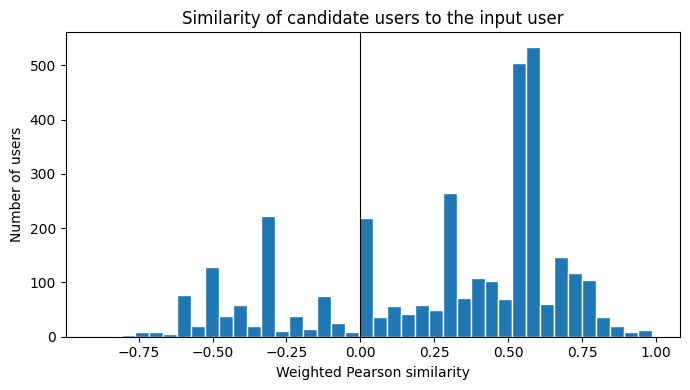

In [25]:
pearsonDF['similarityIndex'].plot(kind='hist', bins=40, figsize=(7, 4), edgecolor='white')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Similarity of candidate users to the input user')
plt.xlabel('Weighted Pearson similarity')
plt.ylabel('Number of users')
plt.tight_layout()
plt.savefig('figures/result.png', dpi=150, bbox_inches='tight')
plt.show()

#### The top x similar users to input user

Now let's get the top 50 users that are most similar to the input. These are the input user's **neighbours**. Only users with a **positive** similarity qualify: a user with opposite tastes is not a useful guide to what the input user will like. `nlargest` returns the rows with the largest values in one step.

In [26]:
# Number of neighbours to use
K_NEIGHBORS = 50

topUsers = pearsonDF[pearsonDF['similarityIndex'] > 0].nlargest(K_NEIGHBORS, 'similarityIndex')
topUsers.head()

,userId,similarityIndex,nCommon
1672,20650,0.986690,5
2922,36711,0.986690,5
3248,40527,0.977692,5
2389,30029,0.969864,5
949,12325,0.961678,5


Now, let's start recommending movies to the input user.

#### Rating of selected users to all movies

We're going to do this by taking the weighted average of the neighbours' ratings, using their similarity as the weight. To do this, we first need every rating given by the users in **topUsers**, which we get by merging the two tables on `userId`. Each rating row then carries that user's `similarityIndex`.

We also attach each neighbour's **average rating** (over all the movies they have rated). The next step uses it to see whether a rating is high or low *for that particular user*.

In [27]:
# Every user's average rating over all of their ratings
userMeans = ratings_df.groupby('userId')['rating'].mean().rename('userMean')

# All ratings of the neighbours, with their similarity and their average rating attached
topUsersRating = (topUsers[['userId', 'similarityIndex']]
                  .merge(ratings_df, on='userId', how='inner')
                  .merge(userMeans, left_on='userId', right_index=True))
topUsersRating.head()

,userId,similarityIndex,movieId,rating,userMean
0,20650,0.98669,1,3.0,3.041068
1,20650,0.98669,2,2.5,3.041068
2,20650,0.98669,29,4.0,3.041068
3,20650,0.98669,32,4.0,3.041068
4,20650,0.98669,39,1.5,3.041068


Users rate on different personal scales: one user gives 4 to an average movie, another gives 4 only to favourites. So for every rating we take its **deviation from that neighbour's own average** (`rating - userMean`). A positive deviation means "liked it more than usual", a negative one means "liked it less than usual".

Then we multiply each deviation by the neighbour's similarity: close neighbours have more say, distant ones less.

In [28]:
# How far each rating is above or below that neighbour's usual rating
topUsersRating['ratingDeviation'] = topUsersRating['rating'] - topUsersRating['userMean']

# Weight each deviation by the neighbour's similarity to the input user
topUsersRating['weightedRating'] = topUsersRating['similarityIndex'] * topUsersRating['ratingDeviation']
topUsersRating.head()

,userId,similarityIndex,movieId,rating,userMean,ratingDeviation,weightedRating
0,20650,0.98669,1,3.0,3.041068,-0.041068,-0.040521
1,20650,0.98669,2,2.5,3.041068,-0.541068,-0.533866
2,20650,0.98669,29,4.0,3.041068,0.958932,0.946169
3,20650,0.98669,32,4.0,3.041068,0.958932,0.946169
4,20650,0.98669,39,1.5,3.041068,-1.541068,-1.520557


Next, we group the table by movie and collect three numbers for every movie with **named aggregation** (`new_column=(source_column, function)`):

* `sum_similarityIndex`: total similarity of the neighbours who rated the movie (the absolute value is used, as the formula requires)
* `sum_weightedRating`: total of their weighted deviations
* `nNeighbors`: how many neighbours rated the movie

In [29]:
# The absolute similarity is the weight used in the denominator of the formula
topUsersRating['absSimilarity'] = topUsersRating['similarityIndex'].abs()

tempTopUsersRating = topUsersRating.groupby('movieId').agg(
    sum_similarityIndex=('absSimilarity', 'sum'),
    sum_weightedRating=('weightedRating', 'sum'),
    nNeighbors=('userId', 'count'),
)
tempTopUsersRating.head()

,sum_similarityIndex,sum_weightedRating,nNeighbors
movieId,,,
1,44.643850,13.122235,50
2,44.643850,-41.837973,50
3,11.646679,-7.602233,13
4,1.769842,0.433993,2
5,10.760455,-9.997896,12


Now we take the weighted average and turn it into a **recommendation score** on the rating scale:

$$
\text{score}(m) = \bar{r}_{\text{input}} + \frac{\sum_{v} \text{sim}(v)\,\big(r_{v,m} - \bar{r}_v\big)}{\sum_{v} |\text{sim}(v)|}
$$

The input user's own average rating is the starting point, and the neighbours' weighted opinion moves it up or down. The score is read like a rating: around the user's average means "an ordinary movie for this user", higher means "neighbours liked it more than usual". It can go slightly above 5 for movies the neighbours were especially enthusiastic about; it is a ranking score, so that is fine.

Two filters make the list reliable:
* **Minimum support:** a movie needs at least `MIN_NEIGHBORS` neighbours who rated it. A movie rated by a single neighbour would get that neighbour's opinion as its full score, and a single opinion is weak evidence.
* **Already watched:** the input movies are removed, since the user has already seen them.

In [30]:
# A movie must be rated by at least this many neighbours to be recommended
MIN_NEIGHBORS = 10

# The input user's average rating is the baseline of the prediction
inputMean = inputMovies['rating'].mean()

recommendation_df = pd.DataFrame({
    'movieId': tempTopUsersRating.index,
    'recommendation score': inputMean + tempTopUsersRating['sum_weightedRating'] / tempTopUsersRating['sum_similarityIndex'],
    'nNeighbors': tempTopUsersRating['nNeighbors'],
}).reset_index(drop=True)

# Keep movies with enough support that the input user hasn't watched yet
recommendation_df = recommendation_df[
    (recommendation_df['nNeighbors'] >= MIN_NEIGHBORS)
    & (~recommendation_df['movieId'].isin(inputMovies['movieId']))
]
recommendation_df.head()

,movieId,recommendation score,nNeighbors
2,3,3.347262,13
4,5,3.070867,12
5,6,4.567909,24
6,7,3.723145,11
9,10,3.950503,31


Now let's sort it and see the top 10 movies that the algorithm recommended! When two movies have the same score, the one rated by more neighbours comes first.

In [31]:
recommendation_df = recommendation_df.sort_values(
    by=['recommendation score', 'nNeighbors'], ascending=False
)
recommendation_df.head(10)

,movieId,recommendation score,nNeighbors
5758,58559,5.299781,20
1312,2019,5.270345,23
2043,3030,5.230125,10
1992,2959,5.200224,47
1135,1732,5.166680,38
1920,2858,5.138892,42
820,1241,5.115203,10
2829,4226,5.103805,43
593,908,5.091584,18
783,1201,5.085771,25


Finally, we attach the titles. A left merge keeps the rows of the left table in their order, so the movies stay in ranking order.

In [32]:
# Top 10 recommendations with title and year, in ranking order
top10 = recommendation_df.head(10).merge(movies_df, on='movieId', how='left')
top10[['movieId', 'title', 'year', 'recommendation score', 'nNeighbors']]

,movieId,title,year,recommendation score,nNeighbors
0,58559,"Dark Knight, The",2008,5.299781,20
1,2019,Seven Samurai (Shichinin no samurai),1954,5.270345,23
2,3030,Yojimbo,1961,5.230125,10
3,2959,Fight Club,1999,5.200224,47
4,1732,"Big Lebowski, The",1998,5.166680,38
5,2858,American Beauty,1999,5.138892,42
6,1241,Dead Alive (Braindead),1992,5.115203,10
7,4226,Memento,2000,5.103805,43
8,908,North by Northwest,1959,5.091584,18
9,1201,"Good, the Bad and the Ugly, The (Buono, il bru...",1966,5.085771,25


### Advantages and Disadvantages of Collaborative Filtering

##### Advantages

*   Takes other users' ratings into consideration
*   Doesn't need to study or extract information from the recommended item
*   Adapts to the user's interests, which might change over time
*   Can recommend surprising items from outside the genres the user usually watches

##### Disadvantages

*   Comparing the input with every other user becomes slow when there are millions of users
*   There might be a low number of similar users to learn from (the rating matrix is very sparse)
*   **Cold start:** a new user with no ratings, or a new movie nobody has rated yet, cannot be handled
*   **Popularity bias:** movies with many ratings are recommended more often than niche ones
*   Privacy issues when trying to learn the user's preferences

Large production systems usually rely on **model-based** collaborative filtering, such as matrix factorization (SVD, ALS) or neural recommenders, which learn compact "taste vectors" for users and movies from the whole rating matrix.